# Medical Image Diagnosis using Vectors and Matrices
**Ex No: 1** | Name: AL NAJEEB A | Reg.no: 192424325 | Course: Deep learning (CSA4702)

Run all cells from top to bottom (Kernel > Restart & Run All). Module 5 updates the weights in place, so re-run from Module 1 if you want to repeat it.

In [1]:
%matplotlib inline

## Module 1: Data and parameter setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- class names and layer sizes ----
classes = ["Normal", "Abnormal"]
features = ["Mean intensity", "Contrast", "Edge density", "Texture entropy"]
n_samples, n_features, n_hidden = 6, 4, 3

# ---- extracted feature matrix (rows = images, columns = features) ----
X = np.array([[0.42, 0.31, 0.18, 0.35],
    [0.45, 0.28, 0.22, 0.40],
    [0.40, 0.33, 0.15, 0.30],
    [0.72, 0.64, 0.58, 0.81],
    [0.68, 0.70, 0.61, 0.77],
    [0.75, 0.59, 0.66, 0.85]])
y = np.array([0, 0, 0, 1, 1, 1])        # 0 = normal, 1 = abnormal

# ---- layer parameters ----
W1 = np.array([[0.8, -0.5, 0.3],
    [0.6, 0.4, -0.7],
    [-0.4, 0.9, 0.5],
    [0.5, -0.3, 0.6]])
b1 = np.array([0.1, -0.15, 0.05])
W2 = np.array([[0.7], [-0.6], [0.9]]); b2 = np.zeros(1)

# ---- sanity checks on shapes and value range ----
assert X.shape == (n_samples, n_features)
assert y.shape == (n_samples,)
assert W1.shape == (n_features, n_hidden)
assert b1.shape == (n_hidden,)
assert W2.shape == (n_hidden, 1)
assert X.min() >= 0 and X.max() <= 1, "features must be normalised"

# ---- table of the input data ----
df1 = pd.DataFrame(X, columns=features, index=[f"S{i+1}" for i in range(6)])
df1["Class"] = np.where(y == 1, "Abnormal", "Normal")
print(df1)
print("X:", X.shape, "W1:", W1.shape, "W2:", W2.shape)

# ---- class-wise summary of the features ----
for c, name in enumerate(classes):
    rows = X[y == c]
    print(name, "images:", len(rows))
    print("  mean:", rows.mean(axis=0).round(3))
    print("  min :", rows.min(axis=0))
    print("  max :", rows.max(axis=0))

# ---- number of trainable parameters ----
n_params = W1.size + b1.size + W2.size + b2.size
print("Trainable parameters:", n_params)
print("Input size:", X.size, "values")
print("Class balance:", np.bincount(y))

# ---- correlation of each feature with the class label ----
corr = [np.corrcoef(X[:, j], y)[0, 1] for j in range(n_features)]
for name, c in zip(features, corr):
    print(f"{name:16s} correlation with class: {c:5.2f}")
print("Features per image:", n_features, "| hidden neurons:", n_hidden)
print("Image names:", list(df1.index))

    Mean intensity  Contrast  Edge density  Texture entropy     Class
S1            0.42      0.31          0.18             0.35    Normal
S2            0.45      0.28          0.22             0.40    Normal
S3            0.40      0.33          0.15             0.30    Normal
S4            0.72      0.64          0.58             0.81  Abnormal
S5            0.68      0.70          0.61             0.77  Abnormal
S6            0.75      0.59          0.66             0.85  Abnormal
X: (6, 4) W1: (4, 3) W2: (3, 1)
Normal images: 3
  mean: [0.423 0.307 0.183 0.35 ]
  min : [0.4  0.28 0.15 0.3 ]
  max : [0.45 0.33 0.22 0.4 ]
Abnormal images: 3
  mean: [0.717 0.643 0.617 0.81 ]
  min : [0.68 0.59 0.58 0.77]
  max : [0.75 0.7  0.66 0.85]
Trainable parameters: 19
Input size: 24 values
Class balance: [3 3]
Mean intensity   correlation with class:  0.99
Contrast         correlation with class:  0.98
Edge density     correlation with class:  0.99
Texture entropy  correlation with class:  0.9

## Module 2: Element-wise (Hadamard) multiplication

           Feature     x    w  x * w
0   Mean intensity  0.42  0.8  0.336
1         Contrast  0.31  0.6  0.186
2     Edge density  0.18 -0.4 -0.072
3  Texture entropy  0.35  0.5  0.175
Sum of x * w = 0.625
Mean intensity     43.69 %
Contrast           24.19 %
Edge density       -9.36 %
Texture entropy    22.76 %
Largest contribution: Mean intensity
Hadamard of all images: (6, 4)
[[ 0.336  0.186 -0.072  0.175]
 [ 0.36   0.168 -0.088  0.2  ]
 [ 0.32   0.198 -0.06   0.15 ]
 [ 0.576  0.384 -0.232  0.405]
 [ 0.544  0.42  -0.244  0.385]
 [ 0.6    0.354 -0.264  0.425]]
Row sums: [0.625 0.64  0.608 1.133 1.105 1.115]


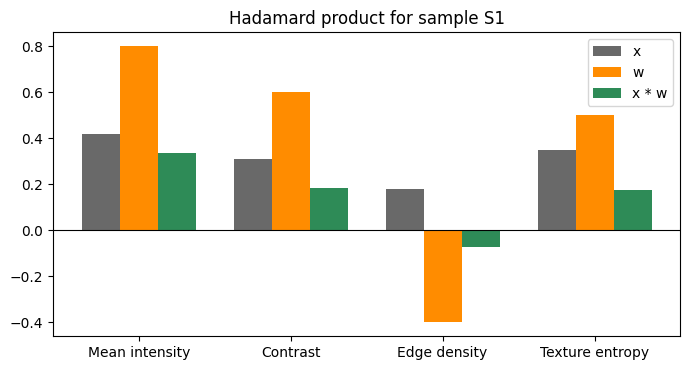

Positive: [0.336 0.186 0.175] | sum 0.697
Negative: [-0.072] | sum -0.072
Net input of neuron 1 (before bias): 0.625
Number of multiplications for all images: 24
Neuron 2 weights  : [-0.5  0.4  0.9 -0.3]
Neuron 2 products : [-0.21   0.124  0.162 -0.105]
Neuron 2 net input: -0.029
S4 products : [ 0.576  0.384 -0.232  0.405]
S4 net input: 1.133


In [3]:
def hadamard_loop(a, b):
    out = np.zeros(len(a))
    for i in range(len(a)):
        out[i] = a[i] * b[i]
    return out

x1 = X[0]                  # feature vector of sample S1
w1 = W1[:, 0]              # weights of hidden neuron 1
had = x1 * w1              # Hadamard product

# ---- check against the loop version and NumPy ----
assert np.allclose(had, hadamard_loop(x1, w1))
assert np.allclose(had, np.multiply(x1, w1))
assert np.allclose(had, w1 * x1)          # the product is commutative

# ---- contribution of each feature ----
df2 = pd.DataFrame({"Feature": features, "x": x1, "w": w1, "x * w": had})
print(df2.round(3))
print("Sum of x * w =", round(had.sum(), 3))

# ---- share of each feature in the neuron input ----
share = had / np.abs(had).sum() * 100
for name, s in zip(features, share):
    print(f"{name:16s} {s:7.2f} %")
print("Largest contribution:", features[int(np.argmax(np.abs(had)))])

# ---- broadcasting the same weights over all six images ----
had_all = X * w1                       # (6 x 4) * (4,) -> (6 x 4)
print("Hadamard of all images:", had_all.shape)
print(had_all.round(3))
print("Row sums:", had_all.sum(axis=1).round(3))
assert np.allclose(had_all[0], had)

pos = np.arange(4)
plt.figure(figsize=(7, 3.8))
plt.bar(pos - 0.25, x1, 0.25, label="x", color="dimgray")
plt.bar(pos, w1, 0.25, label="w", color="darkorange")
plt.bar(pos + 0.25, had, 0.25, label="x * w", color="seagreen")
plt.xticks(pos, features); plt.axhline(0, color="black", lw=0.8)
plt.title("Hadamard product for sample S1"); plt.legend()
plt.tight_layout(); plt.show()

# ---- negative and positive contributions ----
print("Positive:", had[had > 0].round(3), "| sum", had[had > 0].sum().round(3))
print("Negative:", had[had < 0].round(3), "| sum", had[had < 0].sum().round(3))
print("Net input of neuron 1 (before bias):", had.sum().round(3))
print("Number of multiplications for all images:", had_all.size)

# ---- compare two neurons on the same image ----
w2 = W1[:, 1]
had2 = x1 * w2
print("Neuron 2 weights  :", w2)
print("Neuron 2 products :", had2.round(3))
print("Neuron 2 net input:", had2.sum().round(3))

# ---- compare two images on the same neuron ----
x4 = X[3]
had4 = x4 * w1
print("S4 products :", had4.round(3))
print("S4 net input:", had4.sum().round(3))

## Module 3: Matrix multiplication

In [4]:
def matmul_loops(A, B):
    n, k = A.shape
    m = B.shape[1]
    C = np.zeros((n, m))
    for i in range(n):
        for j in range(m):
            for t in range(k):
                C[i, j] += A[i, t] * B[t, j]
    return C

XW = X @ W1                # (6 x 4) . (4 x 3) -> (6 x 3)
ok = np.isclose(XW[0, 0], had.sum())

# ---- the same result from different routes ----
assert np.allclose(XW, matmul_loops(X, W1))
assert np.allclose(XW, np.dot(X, W1))
assert np.allclose(XW, np.matmul(X, W1))
by_neuron = [(X * W1[:, j]).sum(axis=1) for j in range(n_hidden)]
assert np.allclose(XW, np.stack(by_neuron, axis=1))
assert np.allclose(XW.T, W1.T @ X.T)       # transpose rule

# ---- table of the product ----
df3a = pd.DataFrame(XW, columns=["XW_1", "XW_2", "XW_3"], index=df1.index)
print(df3a.round(3))
print("Output shape:", XW.shape, "| equals Hadamard sum:", ok)

# ---- shape rule: (n x k) . (k x m) -> (n x m) ----
print("X  :", X.shape)
print("W1 :", W1.shape)
print("XW :", XW.shape)
print("Inner dimensions match:", X.shape[1] == W1.shape[0])

# ---- cost of the product ----
mults = X.shape[0] * X.shape[1] * W1.shape[1]
adds = X.shape[0] * (X.shape[1] - 1) * W1.shape[1]
print("Multiplications:", mults, "| additions:", adds)

# ---- neuron-wise statistics over the six images ----
print("Mean per neuron:", XW.mean(axis=0).round(3))
print("Min per neuron :", XW.min(axis=0).round(3))
print("Max per neuron :", XW.max(axis=0).round(3))

# ---- difference between the two classes ----
gap = XW[y == 1].mean(axis=0) - XW[y == 0].mean(axis=0)
print("Abnormal - normal mean:", gap.round(3))
print("Neuron with the largest gap:", int(np.argmax(np.abs(gap))) + 1)

# ---- associativity check with the output weights ----
left = (X @ W1) @ W2
right = X @ (W1 @ W2)
print("Associative:", np.allclose(left, right))

# ---- identity matrix leaves the features unchanged ----
I = np.eye(n_features)
assert np.allclose(X @ I, X)
print("X @ I equals X:", np.allclose(X @ I, X))

# ---- column view: each neuron is a weighted sum of feature columns ----
col_view = sum(X[:, k] * W1[k, 0] for k in range(n_features))
print("Neuron 1 by columns:", col_view.round(3))

     XW_1   XW_2   XW_3
S1  0.625 -0.029  0.209
S2  0.640 -0.035  0.289
S3  0.608 -0.023  0.144
S4  1.133  0.175  0.544
S5  1.105  0.258  0.481
S6  1.115  0.200  0.652
Output shape: (6, 3) | equals Hadamard sum: True
X  : (6, 4)
W1 : (4, 3)
XW : (6, 3)
Inner dimensions match: True
Multiplications: 72 | additions: 54
Mean per neuron: [0.871 0.091 0.386]
Min per neuron : [ 0.608 -0.035  0.144]
Max per neuron : [1.133 0.258 0.652]
Abnormal - normal mean: [0.493 0.24  0.345]
Neuron with the largest gap: 1
Associative: True
X @ I equals X: True
Neuron 1 by columns: [0.625 0.64  0.608 1.133 1.105 1.115]


## Module 4: Bias addition and forward propagation

     XW_1   XW_2   XW_3    Z_1    Z_2    Z_3
S1  0.625 -0.029  0.209  0.725 -0.179  0.259
S2  0.640 -0.035  0.289  0.740 -0.185  0.339
S3  0.608 -0.023  0.144  0.708 -0.173  0.194
S4  1.133  0.175  0.544  1.233  0.025  0.594
S5  1.105  0.258  0.481  1.205  0.108  0.531
S6  1.115  0.200  0.652  1.215  0.050  0.702


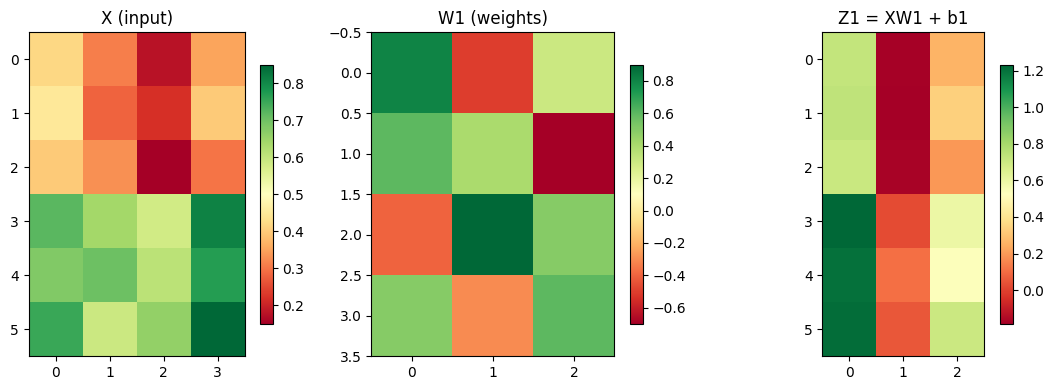

Bias vector b1: [ 0.1  -0.15  0.05]
Shift applied to every row: [ 0.1  -0.15  0.05]
Negative pre-activations: 3
Active hidden units per image: [2 2 2 3 3 3]
Silent neurons for all images: []
Output logits: [0.741 0.823 0.67  1.383 1.257 1.452]
Probabilities: [0.677 0.695 0.662 0.799 0.778 0.81 ]
Predicted class: [1 1 1 1 1 1]
Accuracy before training: 0.5
relu(-2, 0, 3): [0. 0. 3.]
Manual z : [ 0.725 -0.179  0.259]
Manual h : [0.725 0.    0.259]
Manual p : 0.677
X      (6, 4)
Z1     (6, 3)
H      (6, 3)
logit  (6, 1)


In [5]:
relu = lambda z: np.maximum(0, z)
sigmoid = lambda z: 1 / (1 + np.exp(-z))

def forward(X, W1, b1, W2, b2):
    Z = X @ W1 + b1
    Hh = relu(Z)
    return Z, Hh, sigmoid(Hh @ W2 + b2).ravel()

Z1 = XW + b1               # vector addition (bias broadcast to every row)
H = relu(Z1)               # hidden layer activation
p0 = sigmoid(H @ W2 + b2).ravel()      # probability of "abnormal"

# ---- check broadcasting and the forward function ----
assert np.allclose(Z1, XW + np.tile(b1, (n_samples, 1)))
assert np.allclose(Z1 - XW, b1)
Zf, Hf, pf = forward(X, W1, b1, W2, b2)
assert np.allclose(Zf, Z1) and np.allclose(Hf, H) and np.allclose(pf, p0)

df3 = pd.DataFrame(np.hstack([XW, Z1]), index=df1.index,
    columns=["XW_1", "XW_2", "XW_3", "Z_1", "Z_2", "Z_3"])
print(df3.round(3))

fig, ax = plt.subplots(1, 3, figsize=(11, 4))
for a, M, t in zip(ax, [X, W1, Z1], ["X (input)", "W1 (weights)", "Z1 = XW1 + b1"]):
    im = a.imshow(M, cmap="RdYlGn"); a.set_title(t)
    plt.colorbar(im, ax=a, shrink=0.8)
plt.tight_layout(); plt.show()

# ---- effect of the bias and the activation ----
print("Bias vector b1:", b1)
print("Shift applied to every row:", (Z1 - XW)[0])
print("Negative pre-activations:", int((Z1 < 0).sum()))
print("Active hidden units per image:", (H > 0).sum(axis=1))
print("Silent neurons for all images:", np.where((H > 0).sum(axis=0) == 0)[0])

# ---- output layer ----
logit = H @ W2 + b2
print("Output logits:", logit.ravel().round(3))
print("Probabilities:", p0.round(3))
print("Predicted class:", (p0 >= 0.5).astype(int))
print("Accuracy before training:", ((p0 >= 0.5) == y).mean())

# ---- ReLU behaves as expected ----
print("relu(-2, 0, 3):", relu(np.array([-2.0, 0.0, 3.0])))
assert np.all(relu(Z1) >= 0)
assert np.all((p0 > 0) & (p0 < 1))

# ---- manual forward pass for one image ----
z_manual = np.array([sum(X[0, k] * W1[k, j] for k in range(4)) + b1[j]
    for j in range(3)])
h_manual = np.array([max(0.0, v) for v in z_manual])
out_manual = 1 / (1 + np.exp(-(h_manual @ W2[:, 0] + b2[0])))
print("Manual z :", z_manual.round(3))
print("Manual h :", h_manual.round(3))
print("Manual p :", round(out_manual, 3))
assert np.isclose(out_manual, p0[0])

# ---- layer shapes ----
for name, M in [("X", X), ("Z1", Z1), ("H", H), ("logit", logit)]:
    print(f"{name:6s}", M.shape)

## Module 5: Weight update with matrix operations

Loss before training: 0.6809
      H_1    H_2    H_3  P(before)  P(after)  Actual  Predicted
S1  0.725  0.000  0.259      0.677     0.018       0          0
S2  0.740  0.000  0.339      0.695     0.018       0          0
S3  0.708  0.000  0.194      0.662     0.018       0          0
S4  1.233  0.025  0.594      0.799     0.997       1          1
S5  1.205  0.108  0.531      0.778     0.996       1          1
S6  1.215  0.050  0.702      0.810     0.999       1          1
Final loss: 0.0104 | accuracy: 1.0


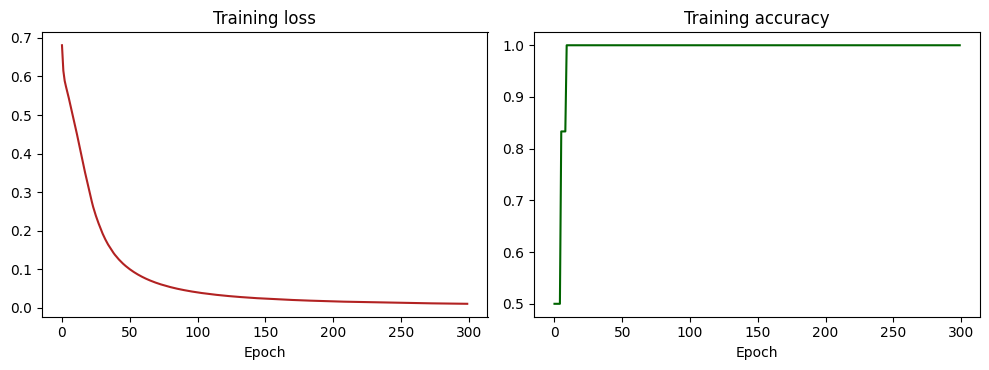

Change in W1: 1.494
Change in W2: 2.358
Gradient norm first / last: 0.1818 / 0.006
TP: 3 TN: 3 FP: 0 FN: 0
Accuracy: 1.0
Precision: 1.0 | recall: 1.0 | F1: 1.0
epoch   1  loss 0.6809  acc 0.50
epoch  50  loss 0.1028  acc 1.00
epoch 100  loss 0.0405  acc 1.00
epoch 200  loss 0.0168  acc 1.00
epoch 300  loss 0.0104  acc 1.00
All images correct from epoch: 10
[[ 1.004 -0.532  0.785]
 [ 1.301  0.37   0.457]
 [ 0.605  0.872  1.994]
 [ 1.294 -0.336  1.867]]


In [6]:
def bce(p, yy):
    return -np.mean(yy * np.log(p + 1e-9) + (1 - yy) * np.log(1 - p + 1e-9))

W1_start, W2_start = W1.copy(), W2.copy()
lr, loss_hist, acc_hist, gnorm = 0.5, [], [], []
print("Loss before training:", round(bce(p0[:, None], y[:, None]), 4))
for epoch in range(300):
    Z = X @ W1 + b1; Hh = relu(Z); p = sigmoid(Hh @ W2 + b2)
    yy = y[:, None]
    loss = bce(p, yy)
    d2 = (p - yy) / len(y)                 # output error
    dW2, db2 = Hh.T @ d2, d2.sum(0)
    d1 = (d2 @ W2.T) * (Z > 0)             # error through ReLU
    dW1, db1 = X.T @ d1, d1.sum(0)
    W2 -= lr * dW2; b2 -= lr * db2
    W1 -= lr * dW1; b1 -= lr * db1
    loss_hist.append(loss); acc_hist.append(((p.ravel() >= 0.5) == y).mean())
    gnorm.append(np.sqrt((dW1 ** 2).sum() + (dW2 ** 2).sum()))

p1 = sigmoid(relu(X @ W1 + b1) @ W2 + b2).ravel()
df4 = pd.DataFrame({"H_1": H[:, 0], "H_2": H[:, 1], "H_3": H[:, 2],
    "P(before)": p0, "P(after)": p1, "Actual": y,
    "Predicted": (p1 >= 0.5).astype(int)}, index=df1.index)
print(df4.round(3))
print("Final loss:", round(loss_hist[-1], 4), "| accuracy:", acc_hist[-1])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(loss_hist, color="firebrick"); ax[0].set_title("Training loss")
ax[1].plot(acc_hist, color="darkgreen"); ax[1].set_title("Training accuracy")
for a in ax: a.set_xlabel("Epoch")
plt.tight_layout(); plt.show()

# ---- how far the weights moved ----
print("Change in W1:", np.abs(W1 - W1_start).max().round(3))
print("Change in W2:", np.abs(W2 - W2_start).max().round(3))
print("Gradient norm first / last:", round(gnorm[0], 4), "/", round(gnorm[-1], 5))

# ---- confusion matrix after training ----
pred = (p1 >= 0.5).astype(int)
tp = int(((pred == 1) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
fp = int(((pred == 1) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
print("TP:", tp, "TN:", tn, "FP:", fp, "FN:", fn)
print("Accuracy:", (tp + tn) / len(y))

# ---- precision, recall and F1 ----
precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = 2 * precision * recall / (precision + recall)
print("Precision:", precision, "| recall:", recall, "| F1:", f1)

# ---- loss at selected epochs ----
for e in [0, 49, 99, 199, 299]:
    print(f"epoch {e + 1:3d}  loss {loss_hist[e]:.4f}  acc {acc_hist[e]:.2f}")

# ---- first epoch where every image was correct ----
first_ok = int(np.argmax(np.array(acc_hist) == 1.0)) + 1
print("All images correct from epoch:", first_ok)

# ---- final first-layer weights ----
print(W1.round(3))